# ЛР № 5. Векторный вход и бинарная классификация на скалярном autograd

Выполнены все 14 кодовых ячеек выданного шаблона. Код перенесён из `lab_guide.pdf`,
класс `Value` сохранён из предыдущей работы; добавлены документационные строки.
Начальные веса, порядок ячеек, шаги обучения, число эпох и проверки сохранены.
Для вычислений нужна только стандартная библиотека Python (`math`). Данные включены в ноутбук.

**Цель:** построить векторные модели из скалярных операций, проверить их градиенты и
обучить три бинарных классификатора: OR → AND → XOR.

Материалы преподавателя: `lab_guide.pdf` и `theory (1).pdf` (Dmitry Vlasov, 2026).
Пояснения и ответы на вопросы приведены после экспериментов.


In [1]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: imports_and_helper
import math


def assert_close(actual, expected, tolerance=1e-9):
    """Проверить абсолютную погрешность численного результата."""
    difference = abs(actual - expected)
    assert difference <= tolerance, (
        f"Ожидалось {expected}, получено {actual}, абсолютная ошибка {difference}"
    )

## Подготовка: скалярный граф и вектор признаков

Сначала перенесите `imports_and_helper`, затем полный класс `value`. Класс остаётся скалярным: вектор входа разворачивается циклом из скалярных операций.


In [2]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: value
class Value:
    """Хранить скаляр, его родителей и локальное правило обратного прохода."""

    def __init__(self, data, parents=(), op=""):
        """Создать вершину с нулевым градиентом и заданными родителями."""
        self.data = float(data)
        self.grad = 0.0
        self.parents = parents
        self.op = op
        self._backward = lambda: None

    def __repr__(self):
        """Вернуть читаемые данные, градиент и метку операции."""
        return f"Value(data={self.data:.6g}, grad={self.grad:.6g}, op={self.op!r})"

    def __add__(self, other):
        """Сложить два скаляра и сохранить локальные производные суммы."""
        other = other if isinstance(other, Value) else Value(other)
        result = Value(self.data + other.data, parents=(self, other), op="+")

        def backward():
            self.grad += result.grad
            other.grad += result.grad

        result._backward = backward
        return result

    __radd__ = __add__

    def __mul__(self, other):
        """Умножить два скаляра и сохранить производные по обоим множителям."""
        other = other if isinstance(other, Value) else Value(other)
        result = Value(self.data * other.data, parents=(self, other), op="*")

        def backward():
            self.grad += result.grad * other.data
            other.grad += result.grad * self.data

        result._backward = backward
        return result

    __rmul__ = __mul__

    def __neg__(self):
        """Изменить знак скаляра с локальной производной минус один."""
        result = Value(-self.data, parents=(self,), op="neg")

        def backward():
            self.grad += result.grad * (-1)

        result._backward = backward
        return result

    def __sub__(self, other):
        """Представить вычитание как сложение с отрицанием."""
        return self + (-other)

    def __rsub__(self, other):
        """Вычесть текущую вершину из обычного числа или другого Value."""
        return other + (-self)

    def __pow__(self, power):
        """Возвести скаляр в постоянную степень и сохранить её производную."""
        result = Value(self.data**power, parents=(self,), op=f"pow({power})")

        def backward():
            local_derivative = power * self.data ** (power - 1)
            self.grad += result.grad * local_derivative

        result._backward = backward
        return result

    def sin(self):
        """Вычислить синус и сохранить множитель cos для обратного прохода."""
        result = Value(math.sin(self.data), parents=(self,), op="sin")

        def backward():
            self.grad += result.grad * math.cos(self.data)

        result._backward = backward
        return result

    def exp(self):
        """Вычислить экспоненту и использовать её значение как производную."""
        result = Value(math.exp(self.data), parents=(self,), op="exp")

        def backward():
            self.grad += result.grad * result.data

        result._backward = backward
        return result

    def log(self):
        """Вычислить натуральный логарифм положительного скаляра."""
        result = Value(math.log(self.data), parents=(self,), op="log")

        def backward():
            self.grad += result.grad * (1 / self.data)

        result._backward = backward
        return result

    def tanh(self):
        """Вычислить tanh и сохранить множитель 1 - tanh(x)**2."""
        result = Value(math.tanh(self.data), parents=(self,), op="tanh")

        def backward():
            self.grad += result.grad * (1 - result.data**2)

        result._backward = backward
        return result

    def backward(self):
        """Вычислить градиенты достижимого графа в обратном топологическом порядке."""
        topo = []
        visited = set()

        def build(node):
            if node not in visited:
                visited.add(node)
                for parent in node.parents:
                    build(parent)
                topo.append(node)

        build(self)
        for node in topo:
            node.grad = 0.0
        self.grad = 1.0
        for node in reversed(topo):
            node._backward()

### Проверка скалярного механизма

Выполните `scalar_graph_refresh`. Он подтверждает, что накопление градиента в ветвящемся графе работает до перехода к векторному входу.


In [3]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: scalar_graph_refresh
a = Value(2.0)
objective = a * a + a
objective.backward()

assert_close(objective.data, 6.0)
assert_close(a.grad, 5.0)
print("Скалярный Value готов: J =", objective.data, ", dJ/da =", a.grad)

Скалярный Value готов: J = 6.0 , dJ/da = 5.0


### Векторные вспомогательные функции

Вставьте `vector_helpers`. Функция `affine` строит скалярный граф для суммы $w_0\cdot1+w_1x_1+w_2x_2$: нулевой вес является весом постоянной координаты и представляет смещение. В общей формуле $\sum_{\alpha=0}^{d}w_\alpha\tilde{x}_{i\alpha}$ индекс $\alpha$ немой, а $i$ свободный; в Python `zip` передаёт очередную пару `weight, feature` без переменной `alpha`. `sigmoid` превращает логит в вероятность. Бинарная кросс-энтропия (англ. binary cross-entropy, BCE) — гладкая функция потерь: отрицательный логарифм вероятности правильной метки. Accuracy оставляем для диагностики, потому что пороговая метка не даёт полезного градиента для `backward()`.


In [4]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: vector_helpers
def affine(weights, features):
    """Собрать скалярный граф суммы w0 * 1 + sum(wj * xj)."""
    # Для фиксированного объекта i: o_i = sum_{alpha=0}^d w_alpha x_tilde[i, alpha].
    # zip передаёт очередную пару без Python-переменной alpha; сумма остаётся в формуле.
    augmented_features = [1.0, *features]
    assert len(weights) == len(augmented_features), (
        "Число весов должно включать вес постоянной координаты"
    )
    total = weights[0] * augmented_features[0]
    for weight, feature in zip(weights[1:], augmented_features[1:]):
        total = total + weight * feature
    return total


def sigmoid(logit):
    """Вычислить вероятность через существующие операции Value."""
    return (1.0 + (-logit).exp()) ** -1


def binary_cross_entropy(probability, target):
    """Построить BCE одного объекта с бинарной меткой."""
    target = float(target)
    assert target in (0.0, 1.0), "Метка бинарной классификации должна быть 0 или 1"
    return -(target * probability.log() + (1.0 - target) * (1.0 - probability).log())


def mean_binary_cross_entropy(model, inputs, targets):
    """Усреднить потери объектов, использующих общие параметры модели."""
    assert len(inputs) == len(targets), "Число объектов и меток должно совпадать"
    assert len(inputs) > 0, "Нужен хотя бы один объект"
    total = Value(0.0)
    # Немая сумма по объектам mu: L = (1 / n) sum_mu ell_mu.
    for features, target in zip(inputs, targets):
        probability = model(features)
        total = total + binary_cross_entropy(probability, target)
    return total * (1.0 / len(inputs))


def predict_label(probability):
    """Вернуть класс 1 при вероятности не меньше 0.5, иначе класс 0."""
    return 1 if probability.data >= 0.5 else 0


def classification_accuracy(model, inputs, targets):
    """Вычислить долю верных бинарных предсказаний."""
    predictions = [predict_label(model(features)) for features in inputs]
    correct = sum(
        prediction == target for prediction, target in zip(predictions, targets)
    )
    return correct / len(targets)


def numerical_gradient(model, parameter, inputs, targets, step=1e-6):
    """Оценить производную центральной разностью и восстановить параметр."""
    original_data = parameter.data
    parameter.data = original_data + step
    loss_plus = mean_binary_cross_entropy(model, inputs, targets).data
    parameter.data = original_data - step
    loss_minus = mean_binary_cross_entropy(model, inputs, targets).data
    parameter.data = original_data
    return (loss_plus - loss_minus) / (2.0 * step)

## Этап 1. Один sigmoid-нейрон с векторным входом

Класс `VectorBinaryNeuron` реализован ниже. Его параметры — долгоживущие объекты `Value`, а признаки остаются обычными числами.


In [5]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: vector_neuron
class VectorBinaryNeuron:
    """Sigmoid-нейрон со смещением и вектором входных признаков."""

    def __init__(self, weights):
        """Создать долгоживущие параметры из начальных чисел."""
        assert len(weights) > 1, "Нужны вес смещения и хотя бы один входной вес"
        self.weights = [Value(weight) for weight in weights]

    def __call__(self, features):
        """Построить свежий граф вероятности класса 1."""
        logit = affine(self.weights, features)
        return sigmoid(logit)

    def parameters(self):
        """Вернуть ссылки на обучаемые Value-параметры."""
        return self.weights

### Прямой проход OR

Выполните `or_forward` и проверьте начальные вероятности до обучения.


In [6]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: or_forward
OR_INPUTS = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
OR_TARGETS = [0, 1, 1, 1]

or_neuron = VectorBinaryNeuron(weights=[0.0, 0.1, -0.2])
or_probabilities = [or_neuron(features).data for features in OR_INPUTS]

assert_close(or_probabilities[0], 0.5)
assert_close(or_probabilities[1], 1.0 / (1.0 + math.exp(0.2)))
assert len(or_neuron.parameters()) == 3
assert all(isinstance(parameter, Value) for parameter in or_neuron.parameters())
print("Начальные вероятности OR:", or_probabilities)

Начальные вероятности OR: [0.5, 0.45016600268752216, 0.52497918747894, 0.47502081252106]


### Градиенты OR

Выполните `or_gradients`. Каждый градиент параметра проверяется центральной разностью.


In [7]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: or_gradients
gradient_or = VectorBinaryNeuron(weights=[0.0, 0.1, -0.2])
or_loss = mean_binary_cross_entropy(gradient_or, OR_INPUTS, OR_TARGETS)
or_loss.backward()

for parameter in gradient_or.parameters():
    expected_gradient = numerical_gradient(
        gradient_or,
        parameter,
        OR_INPUTS,
        OR_TARGETS,
    )
    assert_close(parameter.grad, expected_gradient, tolerance=1e-5)

assert any(abs(parameter.grad) > 1e-8 for parameter in gradient_or.parameters())
print("BCE для OR до обучения:", or_loss.data)
print("Градиенты OR:", [parameter.grad for parameter in gradient_or.parameters()])

BCE для OR до обучения: 0.7200198425221698
Градиенты OR: [-0.2624584993281195, -0.25, -0.2687032961978545]


### Обучение OR

Выполните `train_or`. Требуемый результат: BCE меньше $0.1$ и accuracy $1.0$.


In [8]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: train_or
learning_rate = 0.5
epochs = 300
trained_or = VectorBinaryNeuron(weights=[0.0, 0.1, -0.2])
or_losses = []

for epoch in range(epochs):
    loss = mean_binary_cross_entropy(trained_or, OR_INPUTS, OR_TARGETS)
    loss.backward()
    or_losses.append(loss.data)

    for parameter in trained_or.parameters():
        parameter.data -= learning_rate * parameter.grad

or_predictions = [trained_or(features).data for features in OR_INPUTS]
or_accuracy = classification_accuracy(trained_or, OR_INPUTS, OR_TARGETS)

assert or_losses[-1] < 0.1, or_losses[-1]
assert or_losses[-1] < or_losses[0]
assert or_accuracy == 1.0, or_accuracy
assert all(abs(parameter.data) > 0.1 for parameter in trained_or.parameters())
print("OR: loss в первой эпохе:", or_losses[0])
print("OR: loss в последней эпохе:", or_losses[-1])
print("OR: вероятности:", or_predictions)
print("OR: точность:", or_accuracy)

OR: loss в первой эпохе: 0.7200198425221698
OR: loss в последней эпохе: 0.06236374801543139
OR: вероятности: [0.13200433213232757, 0.9478517568657973, 0.9482967689524896, 0.9995440205950941]
OR: точность: 1.0


## Этап 2. Один скрытый нейрон и один выходной нейрон

Класс `OneHiddenBinaryClassifier` реализован ниже. Скрытый нейрон использует $\tanh$, выходной — sigmoid. AND выбран здесь для наблюдения градиента через композицию, хотя один sigmoid-нейрон способен классифицировать AND без скрытого слоя.


In [9]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: one_hidden_model
class OneHiddenBinaryClassifier:
    """Классификатор с одним скрытым tanh-нейроном и sigmoid-выходом."""

    def __init__(self, hidden_weights, output_weights):
        """Создать параметры скрытого и выходного нейронов."""
        assert len(hidden_weights) > 1, "Нужны вес смещения и хотя бы один входной вес"
        assert len(output_weights) == 2, (
            "Выходу нужны вес смещения и вес скрытого состояния"
        )
        self.hidden_weights = [Value(weight) for weight in hidden_weights]
        self.output_weights = [Value(weight) for weight in output_weights]

    def hidden_state(self, features):
        """Вычислить скрытый признак через tanh аффинной суммы."""
        # Один фиксированный скрытый нейрон; affine сворачивает входные координаты alpha.
        hidden_logit = affine(self.hidden_weights, features)
        return hidden_logit.tanh()

    def __call__(self, features):
        """Преобразовать скрытый признак в вероятность класса 1."""
        hidden = self.hidden_state(features)
        output_logit = affine(self.output_weights, [hidden])
        return sigmoid(output_logit)

    def parameters(self):
        """Собрать ссылки на три скрытых и два выходных параметра."""
        return self.hidden_weights + self.output_weights

### Градиенты AND

Выполните `and_gradients`. Проверка показывает прохождение градиента через выходной и скрытый нейроны.


In [10]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: and_gradients
AND_INPUTS = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
AND_TARGETS = [0, 0, 0, 1]

gradient_and = OneHiddenBinaryClassifier(
    hidden_weights=[0.0, 0.1, -0.2],
    output_weights=[0.0, 0.3],
)
and_loss = mean_binary_cross_entropy(gradient_and, AND_INPUTS, AND_TARGETS)


and_loss.backward()

for parameter in gradient_and.parameters():
    expected_gradient = numerical_gradient(
        gradient_and,
        parameter,
        AND_INPUTS,
        AND_TARGETS,
    )
    assert_close(parameter.grad, expected_gradient, tolerance=1e-5)

assert_close(gradient_and.hidden_weights[1].grad, 0.0)
assert any(abs(parameter.grad) > 1e-8 for parameter in gradient_and.parameters())
print("BCE для AND до обучения:", and_loss.data)
print("Градиенты AND:", [parameter.grad for parameter in gradient_and.parameters()])

BCE для AND до обучения: 0.6933861312886811
Градиенты AND: [0.07247243881438471, 0.0, -0.0027100690521792425, 0.24630029365404474, 0.0013478006952490802]


### Обучение AND

Выполните `train_and`. Требуемый результат: BCE меньше $0.05$ и accuracy $1.0$.


In [11]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: train_and
learning_rate = 0.3
epochs = 300
trained_and = OneHiddenBinaryClassifier(
    hidden_weights=[0.0, 0.1, -0.2],
    output_weights=[0.0, 0.3],
)
and_losses = []

for epoch in range(epochs):
    loss = mean_binary_cross_entropy(trained_and, AND_INPUTS, AND_TARGETS)
    loss.backward()
    and_losses.append(loss.data)

    for parameter in trained_and.parameters():
        parameter.data -= learning_rate * parameter.grad

and_predictions = [trained_and(features).data for features in AND_INPUTS]
and_accuracy = classification_accuracy(trained_and, AND_INPUTS, AND_TARGETS)

assert and_losses[-1] < 0.05, and_losses[-1]
assert and_losses[-1] < and_losses[0]
assert and_accuracy == 1.0, and_accuracy
assert all(abs(parameter.grad) > 1e-8 for parameter in trained_and.parameters())
print("AND: loss в первой эпохе:", and_losses[0])
print("AND: loss в последней эпохе:", and_losses[-1])
print("AND: вероятности:", and_predictions)
print("AND: точность:", and_accuracy)

AND: loss в первой эпохе: 0.6933861312886811
AND: loss в последней эпохе: 0.022928442324803712
AND: вероятности: [0.0037193584223685085, 0.019203018766091182, 0.019204423277084767, 0.9524535868989039]
AND: точность: 1.0


### Зачем в маршруте нужен XOR

После AND проверяем не механизм градиента, а выразительность архитектуры. Один скрытый нейрон создаёт только одну линейную границу при классификации, поэтому XOR ему недоступен. XOR — минимальный учебный тест, а не прикладная целевая функция этой лабораторной.


## Этап 3. Скрытый слой из двух нейронов и XOR

Класс `HiddenLayerBinaryClassifier` реализован ниже. Два скрытых нейрона строят два разных нелинейных признака, которые объединяет sigmoid-выход. Это минимальный тест выразительности; в MLP та же идея переносится на большие вещественные векторы и большее число скрытых нейронов.


In [12]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: xor_model
class HiddenLayerBinaryClassifier:
    """Классификатор со скрытым слоем tanh и одним sigmoid-выходом."""

    def __init__(self, hidden_layer_weights, output_weights):
        """Создать скрытый слой согласованной размерности и выход."""
        assert len(hidden_layer_weights) > 0, "Нужен хотя бы один скрытый нейрон"
        feature_count = len(hidden_layer_weights[0])
        assert feature_count > 1, (
            "У скрытого нейрона нужны смещение и хотя бы один вход"
        )
        assert all(len(weights) == feature_count for weights in hidden_layer_weights), (
            "Все скрытые нейроны должны иметь одинаковое число входов"
        )
        assert len(output_weights) == len(hidden_layer_weights) + 1, (
            "Выходу нужны вес смещения и веса всех скрытых состояний"
        )
        self.hidden_weights = [
            [Value(weight) for weight in weights] for weights in hidden_layer_weights
        ]
        self.output_weights = [Value(weight) for weight in output_weights]

    def hidden_states(self, features):
        """Построить отдельный нелинейный признак для каждого скрытого нейрона."""
        # Каждая строка весов задаёт фиксированный h; список hidden сворачивается по beta.
        return [affine(weights, features).tanh() for weights in self.hidden_weights]

    def __call__(self, features):
        """Объединить скрытые признаки и вернуть вероятность класса 1."""
        hidden = self.hidden_states(features)
        output_logit = affine(self.output_weights, hidden)
        return sigmoid(output_logit)

    def parameters(self):
        """Вернуть ссылки на все скрытые и выходные параметры."""
        parameters = []
        for weights in self.hidden_weights:
            parameters.extend(weights)
        parameters.extend(self.output_weights)
        return parameters

### Градиенты XOR

Выполните `xor_gradients`. Центральная разность должна совпасть с обратным проходом для всех девяти параметров.


In [13]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: xor_gradients
XOR_INPUTS = [
    [0.0, 0.0],
    [0.0, 1.0],
    [1.0, 0.0],
    [1.0, 1.0],
]
XOR_TARGETS = [0, 1, 1, 0]

gradient_xor = HiddenLayerBinaryClassifier(
    hidden_layer_weights=[[0.1, 0.4, -0.3], [-0.1, -0.2, 0.5]],
    output_weights=[0.0, 0.3, -0.4],
)
xor_loss = mean_binary_cross_entropy(gradient_xor, XOR_INPUTS, XOR_TARGETS)
xor_loss.backward()

for parameter in gradient_xor.parameters():
    expected_gradient = numerical_gradient(
        gradient_xor,
        parameter,
        XOR_INPUTS,
        XOR_TARGETS,
    )
    assert_close(parameter.grad, expected_gradient, tolerance=1e-5)

assert len(gradient_xor.parameters()) == 9
assert any(abs(parameter.grad) > 1e-8 for parameter in gradient_xor.parameters())
print("BCE для XOR до обучения:", xor_loss.data)
print("Градиенты XOR:", [parameter.grad for parameter in gradient_xor.parameters()])

BCE для XOR до обучения: 0.6974895138776747
Градиенты XOR: [0.008525444612619417, 0.009933955272260968, -0.004147157354024503, -0.011573946274921518, -0.007627296378057938, -0.00029512097101965645, 0.005836030048295041, 0.014154145503698236, -0.009161276776075637]


### Обучение XOR

Выполните `train_xor`. Требуемый результат: BCE меньше $0.03$ и accuracy $1.0$.


In [14]:
# VECTOR_BINARY_CLASSIFICATION_ESSENTIALS_CELL: train_xor
learning_rate = 0.5
epochs = 500
trained_xor = HiddenLayerBinaryClassifier(
    hidden_layer_weights=[[0.1, 0.4, -0.3], [-0.1, -0.2, 0.5]],
    output_weights=[0.0, 0.3, -0.4],
)
xor_losses = []

for epoch in range(epochs):
    loss = mean_binary_cross_entropy(trained_xor, XOR_INPUTS, XOR_TARGETS)
    loss.backward()
    xor_losses.append(loss.data)

    for parameter in trained_xor.parameters():
        parameter.data -= learning_rate * parameter.grad

xor_predictions = [trained_xor(features).data for features in XOR_INPUTS]
xor_accuracy = classification_accuracy(trained_xor, XOR_INPUTS, XOR_TARGETS)

assert xor_losses[-1] < 0.03, xor_losses[-1]
assert xor_losses[-1] < xor_losses[0]
assert xor_accuracy == 1.0, xor_accuracy
assert all(abs(parameter.data) > 0.1 for parameter in trained_xor.parameters())
print("XOR: loss в первой эпохе:", xor_losses[0])
print("XOR: loss в последней эпохе:", xor_losses[-1])
print("XOR: вероятности:", xor_predictions)
print("XOR: точность:", xor_accuracy)

XOR: loss в первой эпохе: 0.6974895138776747
XOR: loss в последней эпохе: 0.025122785704812224
XOR: вероятности: [0.018893036023121788, 0.9676336766552224, 0.9684286235905825, 0.01592091709544799]
XOR: точность: 1.0


## Диагностика

При ошибке сверяйте порядок запуска, размерности признаков и весов, порядок `backward()` и обновления параметров, а также знак шага градиентного спуска. Полный список находится в guide.


## Чек-лист перед сдачей

- [ ] Все `assert` пройдены.
- [ ] OR, AND и XOR достигли требуемых loss и accuracy.
- [ ] Я могу объяснить общие параметры датасета и ограничение одного скрытого нейрона.

## Вопросы для самопроверки

Ответьте письменно на вопросы для самопроверки из выданного текста лабораторной работы.


## Результаты выполненного запуска

| Задача | Архитектура | Параметры | Эпохи / шаг | Начальная BCE | Последняя BCE* | Точность |
|---|---|---:|---|---:|---:|---:|
| OR | 1 sigmoid | 3 | 300 / 0.5 | 0.720020 | 0.062364 | 100% |
| AND | 1 tanh → sigmoid | 5 | 300 / 0.3 | 0.693386 | 0.022928 | 100% |
| XOR | 2 tanh → sigmoid | 9 | 500 / 0.5 | 0.697490 | 0.025123 | 100% |

*В журнал записывается BCE **до обновления весов** в соответствующей эпохе, как в методичке.
При повторном прямом проходе после последнего обновления BCE равна
OR: 0,062167; AND: 0,022805; XOR: 0,025026. Прогнозы вычислены после последнего обновления.

Все исходные `assert` прошли. Максимальное расхождение автоградиента с центральной
разностью по всем 17 параметрам трёх моделей — меньше $1.3\cdot10^{-10}$
при допуске $10^{-5}$. Нулевой начальный градиент первого реального входного веса AND
подтверждён численной проверкой: при заданной инициализации вклады объектов компенсируются.

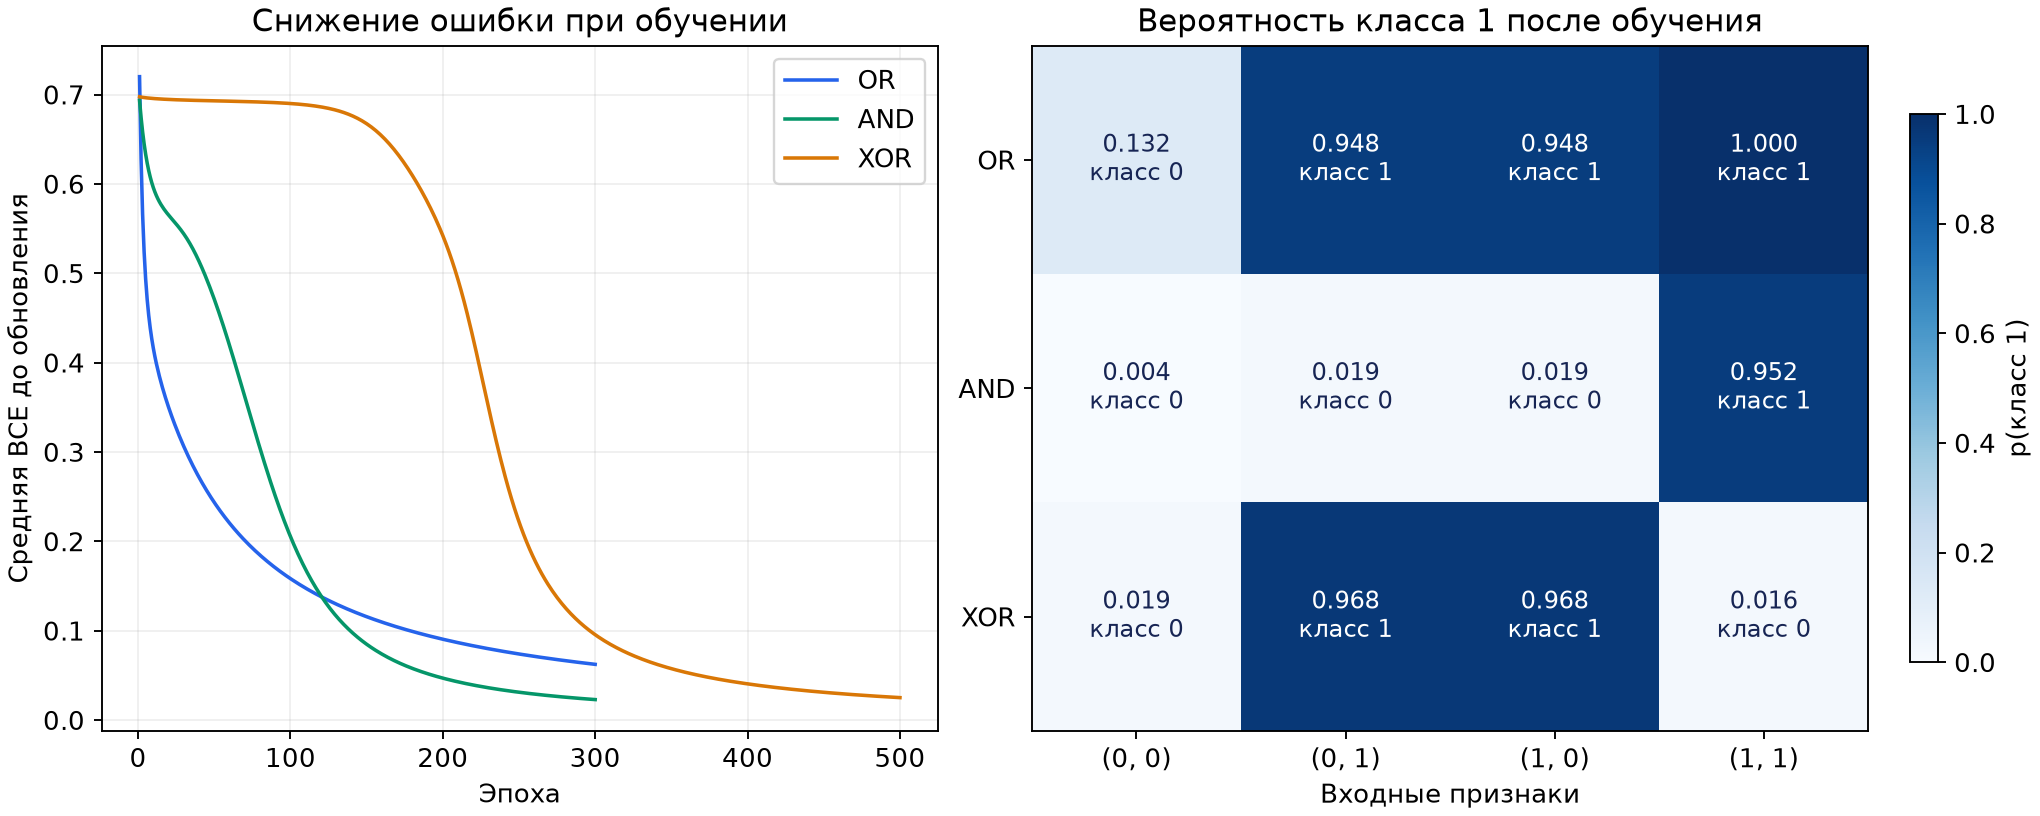

График сохранён по результатам этого запуска; повторное выполнение вычислительных ячеек не требует Matplotlib.

## Ответы на вопросы для самопроверки

**1. Какие скалярные вершины создаёт `affine` для двух признаков?**

Входные обучаемые листья — $w_0,w_1,w_2$. Числа $1,x_1,x_2$ оборачиваются в константные листья.
Три узла умножения вычисляют $w_0\cdot1$, $w_1x_1$, $w_2x_2$; два узла сложения
собирают $z=(w_0\cdot1+w_1x_1)+w_2x_2$. Веса входят в `parameters()`, а константы — нет.
Значение признака задаётся данными, поэтому градиентный спуск его не изменяет.

**2. Почему одна ссылка на `weights[0]` даёт сумму вкладов всех объектов?**

Вызовы модели используют один и тот же объект `Value` смещения, а не его копии.
Потери объектов объединены в один граф средней BCE. При обратном проходе все пути
приходят к общему листу; `+=` накапливает вклады:
$\partial L/\partial w_0=\frac1n\sum_i(p_i-y_i)$.
Сброс градиентов выполняется один раз перед обходом, а не перед каждым вкладом.

**3. Где хранится вероятность класса 1?**

В выходном узле `sigmoid`, его `data` лежит между 0 и 1. Скрытый `tanh` возвращает
признак в интервале $(-1,1)$ и не является вероятностью. Класс равен 1 при $p\ge0.5$.

**4. Почему BCE вместе с sigmoid даёт градиент логита $p-y$?**

Для одного объекта $\ell=-y\ln p-(1-y)\ln(1-p)$ и $p=\sigma(z)$.
По правилу цепочки:
$$\frac{\partial\ell}{\partial z}
=\left(-\frac yp+\frac{1-y}{1-p}\right)p(1-p)=p-y.$$
Для средней потери вклад объекта равен $(p_i-y_i)/n$;
$\partial L/\partial w_j=\frac1n\sum_i(p_i-y_i)\tilde x_{ij}$.
Автодифференцирование получает это выражение проходом по скалярным узлам.

**5. Что нарушится при обновлении `parameter.data` до `loss.backward()`?**

Граф уже вычислен со старыми весами, а локальные обработчики операций читают `data`
родителей. Если изменить параметры заранее, в обратном проходе смешаются значения
разных состояний модели и градиент может оказаться неверным. Правильный порядок:
свежий прямой проход → средняя BCE → `backward()` → обновление всех весов.

**6. Почему одинаковые скрытые нейроны не приобретают разные роли?**

При полной симметрии — одинаковых входных весах, смещениях **и весах связи с выходом** —
нейроны дают одинаковые состояния, получают одинаковые градиенты и одинаково обновляются.
Детерминированный градиентный спуск эту симметрию не нарушает. Поэтому в XOR использованы
разные начальные веса. Если одинаковы только входные веса, а выходные связи различны,
градиенты скрытых нейронов уже могут различаться.

**7. Почему XOR — тест выразительности, а не прикладная задача?**

Четыре точки позволяют отделить ограничение архитектуры от сложности реальных данных:
XOR нельзя разделить одной прямой. Один скрытый `tanh` и монотонный sigmoid-выход
дают классификатор с единственной линейной границей (либо постоянным классом).
Два скрытых нейрона создают разные нелинейные признаки, и их комбинация решает XOR.
Практический смысл работы — понять этот механизм, который затем используется в MLP.

## Вывод

Векторный вход не требует векторного класса `Value`: списки и циклы собирают граф из
скалярных операций. OR проверяет один sigmoid-нейрон, AND — прохождение градиента
через скрытый tanh, XOR — выразительность двух скрытых нейронов. AND сам по себе
линейно разделим; скрытый слой здесь нужен для изучения композиции.

На каждой эпохе строится новый граф, но обучаемые листья остаются теми же объектами.
Центральные разности проверяют все 3, 5 и 9 параметров соответствующих моделей с
допуском $10^{-5}$. Это проверка реализации градиента, а не способ обучения.

Accuracy измерена на четырёх учебных объектах, составляющих полные таблицы истинности.
Она подтверждает выполнение учебных условий и не оценивает качество на реальных данных.
